# 04 — MobileNetV3

Pelatihan **MobileNetV3** (transfer learning, *feature extraction*) untuk klasifikasi 5 kelas kualitas green bean kopi.

MobileNetV3 memakai input 224x224 dan jauh lebih kecil dari ResNet-50 dalam jumlah parameter. Perlu dicatat: lebih kecil belum tentu lebih cepat di GPU — depthwise convolution bersifat memory-bound.

Hyperparameter sengaja **seragam** dengan dua arsitektur lain (30 epoch, batch 32, Adam, lr 0.001) agar perbedaan skor dapat diatribusikan ke arsitekturnya, bukan ke pengaturan pelatihan.

Dataset dibaca dari `data/crops/` yang **sudah** diaugmentasi offline, jadi transform di sini hanya resize + normalisasi ImageNet.

## 1. Setup & imports

In [1]:
# Bootstrap: tambahkan root proyek ke sys.path agar modul src/ & configs/ dapat diimpor.
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: c:\Users\DZXP\Documents\ta-green-bean


In [2]:
import pandas as pd
import torch
from torch.utils.data import DataLoader

from configs.base_config import (
    ANALYSIS_DIR,
    CLASS_NAMES,
    CLASS_WEIGHTS_STRATEGY,
    CROPS_DIR,
    DEVICE,
    FIGURES_DIR,
    IMBALANCE_STRATEGY,
    METRICS_DIR,
    MODELS_DIR,
    NUM_CLASSES,
    RANDOM_SEED,
    TTA_MODE,
)
from configs.cnn_config import CNN_CONFIG
from src.analysis.confusion_analysis import (
    error_pattern_analysis,
    generate_classification_report_table,
    plot_confusion_matrix,
)
from src.analysis.efficiency_analysis import measure_model_efficiency
from src.analysis.feature_visualization import extract_features, save_features
from src.analysis.learning_curves import plot_learning_curves
from src.analysis.style import apply_plot_style
from src.data.dataset import GreenBeanDataset
from src.data.transforms import get_transforms
from src.evaluation.metrics import (
    compute_defect_metrics,
    compute_metrics,
    compute_per_class_metrics,
)
from src.evaluation.efficiency import measure_inference_time
from src.evaluation.predict import collect_predictions, save_predictions
from src.evaluation.tta import TTA_VIEWS, wrap_tta
from src.models.model_factory import get_model
from src.training.imbalance import create_weighted_sampler, describe_imbalance
from src.training.train_cnn import train_cnn
from src.utils.io import load_checkpoint, save_json
from src.utils.seed import set_seed

apply_plot_style()
set_seed(RANDOM_SEED)
print('device:', DEVICE, '| kelas:', NUM_CLASSES)

device: cuda | kelas: 5


## 2. Konfigurasi

Strategi imbalance dapat diganti di sini: `none`, `class_weights`, `weighted_sampler`, atau `focal_loss`. Untuk perbandingan arsitektur yang adil, pakai strategi **yang sama** pada ketiga notebook.

In [3]:
MODEL_NAME = 'mobilenetv3'
STRATEGY = IMBALANCE_STRATEGY  # ganti di sini untuk eksperimen imbalance

config = dict(CNN_CONFIG[MODEL_NAME])
config['imbalance_strategy'] = STRATEGY
config['class_weights_strategy'] = CLASS_WEIGHTS_STRATEGY
config

{'input_size': 224,
 'epochs': 30,
 'batch_size': 32,
 'learning_rate': 0.001,
 'optimizer': 'adam',
 'loss': 'cross_entropy',
 'num_classes': 5,
 'imbalance_strategy': 'class_weights',
 'class_weights_strategy': 'balanced'}

## 3. DataLoader

In [4]:
batch_size = int(config['batch_size'])

train_ds = GreenBeanDataset(CROPS_DIR / 'train', transform=get_transforms(MODEL_NAME, 'train'))
val_ds = GreenBeanDataset(CROPS_DIR / 'valid', transform=get_transforms(MODEL_NAME, 'valid'))
test_ds = GreenBeanDataset(CROPS_DIR / 'test', transform=get_transforms(MODEL_NAME, 'test'))

if len(train_ds) == 0:
    raise FileNotFoundError(
        'data/crops/train kosong. Jalankan notebook 02, atau: '
        'python -m scripts.crop_dataset && python -m scripts.augment_dataset'
    )

sampler = None
if STRATEGY == 'weighted_sampler':
    sampler = create_weighted_sampler(train_ds.labels, num_classes=NUM_CLASSES, seed=RANDOM_SEED)

train_loader = DataLoader(
    train_ds, batch_size=batch_size, shuffle=sampler is None, sampler=sampler,
    pin_memory=DEVICE.startswith('cuda'),
)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

for name, ds in (('train', train_ds), ('valid', val_ds), ('test', test_ds)):
    print(f'{name:6} n={len(ds):6,}  {ds.class_counts()}  {ds.augmentation_counts()}')

print()
print('ketimpangan train:', describe_imbalance(train_ds.class_counts()))

train  n= 4,750  {'good': 868, 'black': 927, 'chipped': 945, 'dry_pods': 1014, 'insect_damage': 996}  {'original': 2162, 'augmented': 2588}
valid  n=   822  {'good': 404, 'black': 133, 'chipped': 93, 'dry_pods': 93, 'insect_damage': 99}  {'original': 822, 'augmented': 0}
test   n=   863  {'good': 435, 'black': 132, 'chipped': 96, 'dry_pods': 93, 'insect_damage': 107}  {'original': 863, 'augmented': 0}

ketimpangan train: {'total': 4750, 'majority_class': 'dry_pods', 'minority_class': 'good', 'imbalance_ratio': 1.1682, 'majority_share': 0.2135}


## 4. Bangun model

In [5]:
model = get_model(MODEL_NAME, num_classes=NUM_CLASSES, pretrained=True)

n_total = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'parameter total     : {n_total:,}')
print(f'parameter trainable : {n_trainable:,}  ({n_trainable / n_total * 100:.4f}%)')
print('-> hanya head klasifikasi yang dilatih; backbone dibekukan.')

parameter total     : 4,208,437
parameter trainable : 6,405  (0.1522%)
-> hanya head klasifikasi yang dilatih; backbone dibekukan.


## 5. Pelatihan

Log per-epoch juga ditulis ke `results/logs/`. Pelatihan 30 epoch memakan waktu; jalankan sel ini sekali lalu biarkan selesai.

In [6]:
output_dir = MODELS_DIR / MODEL_NAME

history = train_cnn(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    config=config,
    output_dir=output_dir,
    model_name=MODEL_NAME,
    device=DEVICE,
    imbalance_strategy=STRATEGY,
)

print(f"best_val_acc = {history['best_val_acc']:.4f} (epoch {history['best_epoch']})")
print('checkpoint  =', history['best_model_path'])

best_val_acc = 0.7810 (epoch 9)
checkpoint  = C:\Users\DZXP\Documents\ta-green-bean\results\models\mobilenetv3\mobilenetv3_best_epoch9_acc0.78.pt


## 6. Kurva pembelajaran

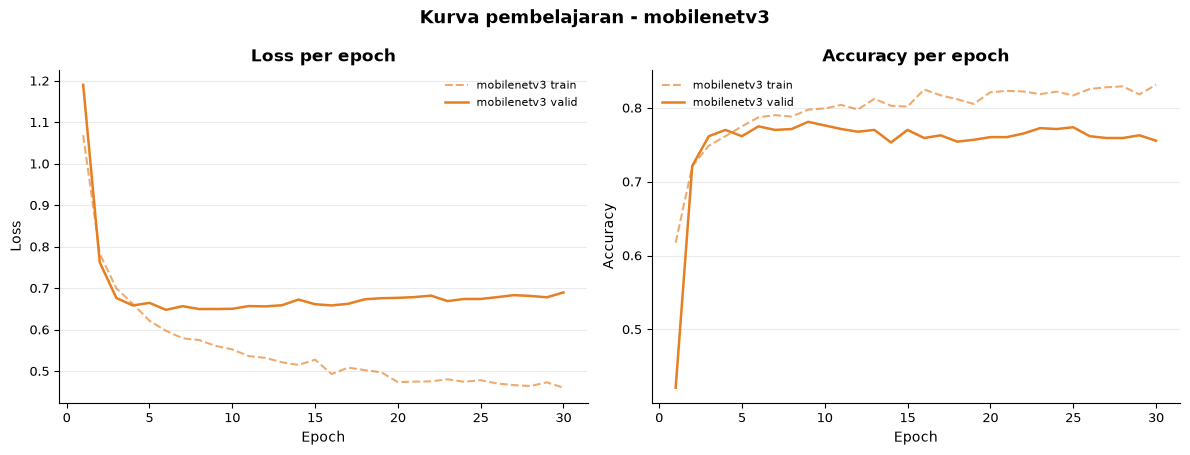

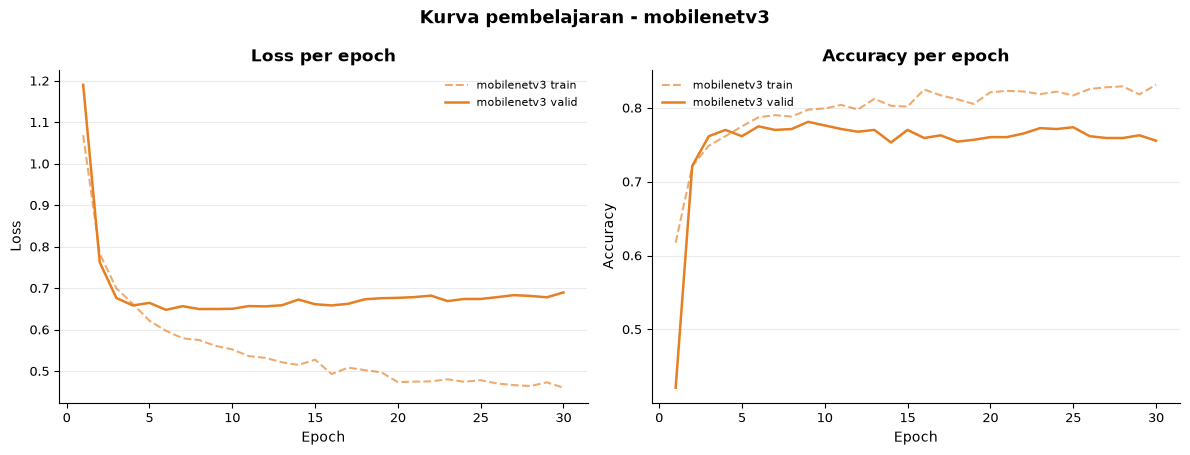

In [7]:
plot_learning_curves(
    {MODEL_NAME: history},
    output_path=FIGURES_DIR / f'{MODEL_NAME}_learning_curves.png',
    title=f'Kurva pembelajaran - {MODEL_NAME}',
)

## 7. Evaluasi pada split test

Sebelum evaluasi, **checkpoint terbaik** (val accuracy tertinggi) dimuat ulang dari disk, lalu prediksi dibuat dengan TTA (`TTA_MODE` di `configs/base_config.py`, default D4 = 8 orientasi). Prosedurnya identik dengan `python -m scripts.evaluate`, sehingga angka notebook sama dengan angka resmi di `results/`.

Tanpa langkah ini, evaluasi memakai bobot epoch terakhir (epoch 30), bukan epoch terbaik.

In [8]:
# Muat checkpoint terbaik -- sama dengan scripts.evaluate (bukan bobot epoch terakhir).
best_model_path = Path(history['best_model_path'])
load_checkpoint(model, best_model_path, map_location=DEVICE)
model = model.to(DEVICE).eval()
tta_model = wrap_tta(model, TTA_MODE)

print('checkpoint :', best_model_path.name)
print('TTA        :', TTA_MODE, f'({TTA_VIEWS[TTA_MODE]} orientasi)')

checkpoint : mobilenetv3_best_epoch9_acc0.78.pt
TTA        : d4 (8 orientasi)


In [9]:
predictions = collect_predictions(
    tta_model, test_loader, device=DEVICE, class_names=CLASS_NAMES
)  # TTA D4 (configs.base_config.TTA_MODE)
y_true = predictions['y_true'].tolist()
y_pred = predictions['y_pred'].tolist()

metrics = compute_metrics(y_true, y_pred)
defect = compute_defect_metrics(y_true, y_pred, CLASS_NAMES)
per_class = compute_per_class_metrics(y_true, y_pred, CLASS_NAMES)

print('--- metrik makro 5 kelas ---')
for key, value in metrics.items():
    print(f'{key:<10}: {value:.4f}')
print()
print('--- layak vs cacat ---')
for key, value in defect.items():
    print(f'{key:<18}: {value:.4f}')

--- metrik makro 5 kelas ---
accuracy  : 0.8111
precision : 0.7596
recall    : 0.7525
f1        : 0.7542

--- layak vs cacat ---
defect_accuracy   : 0.9038
defect_precision  : 0.9059
defect_recall     : 0.8995
defect_f1         : 0.9027
defect_miss_rate  : 0.1005


In [10]:
generate_classification_report_table(y_true, y_pred, CLASS_NAMES)

,precision,recall,f1,support
kelas,,,,
good,0.9018,0.9080,0.9049,435
black,0.7463,0.7576,0.7519,132
chipped,0.6106,0.7188,0.6603,96
dry_pods,0.8941,0.8172,0.8539,93
insect_damage,0.6452,0.5607,0.6000,107
macro avg,0.7596,0.7525,0.7542,863
weighted avg,0.8130,0.8111,0.8110,863


## 8. Confusion matrix

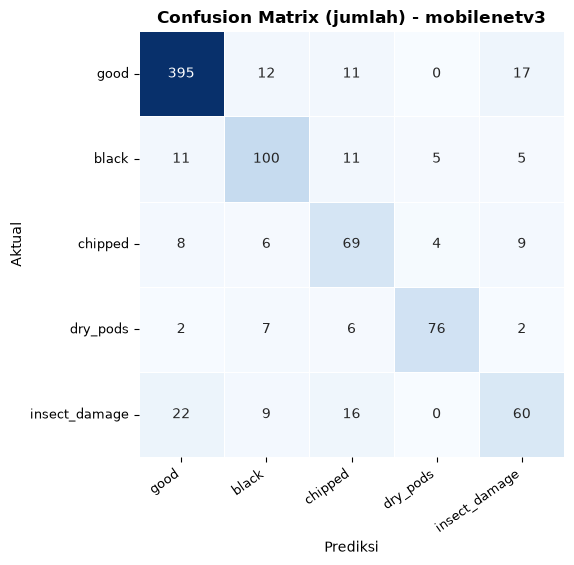

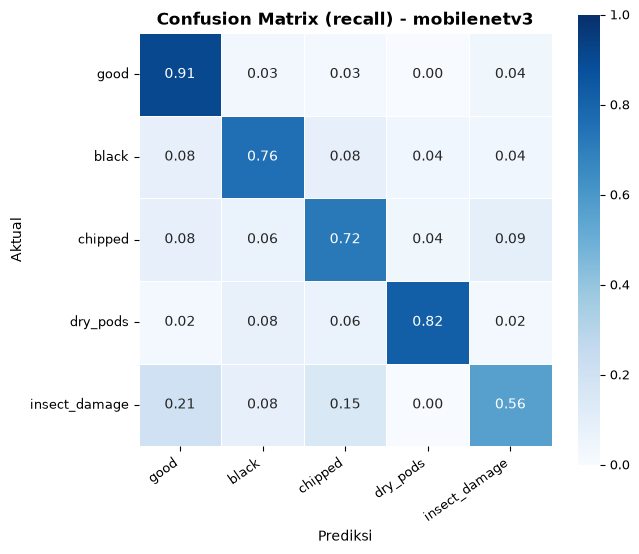

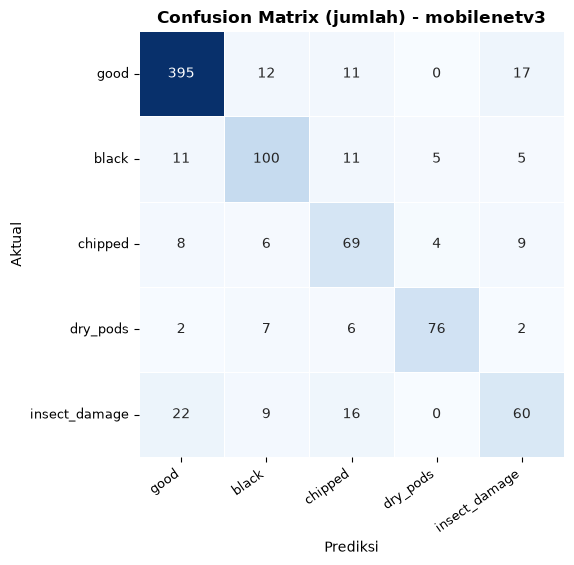

In [11]:
plot_confusion_matrix(
    y_true, y_pred,
    class_names=CLASS_NAMES,
    normalize='true',
    title=f'Confusion Matrix (recall) - {MODEL_NAME}',
    output_path=FIGURES_DIR / f'{MODEL_NAME}_confusion_matrix.png',
)

plot_confusion_matrix(
    y_true, y_pred,
    class_names=CLASS_NAMES,
    normalize=None,
    title=f'Confusion Matrix (jumlah) - {MODEL_NAME}',
    output_path=FIGURES_DIR / f'{MODEL_NAME}_confusion_matrix_counts.png',
)

## 9. Efisiensi

In [12]:
input_size = int(config['input_size'])
efficiency = measure_model_efficiency(
    model,
    input_shape=(1, 3, input_size, input_size),
    device=DEVICE,
    checkpoint_path=best_model_path,
)
efficiency['tta'] = TTA_MODE
efficiency['tta_views'] = TTA_VIEWS[TTA_MODE]
if TTA_MODE != 'none':
    efficiency['inference_time_ms_tta'] = measure_inference_time(
        tta_model, input_shape=(1, 3, input_size, input_size), device=DEVICE
    )
pd.Series(efficiency)

params_total               4208437
params_trainable              6405
model_size_mb               16.054
inference_time_ms           6.6632
throughput_img_per_s        150.08
flops                    215316160
input_size                     224
device                        cuda
checkpoint_size_mb          16.257
tta                             d4
tta_views                        8
inference_time_ms_tta    52.065094
dtype: object

## 10. Simpan artefak

Formatnya sama persis dengan keluaran `python -m scripts.evaluate`, sehingga notebook 06-10 dapat membacanya tanpa perubahan.

In [13]:
errors = error_pattern_analysis(y_true, y_pred, CLASS_NAMES, top_n=10)

report = {
    'model': MODEL_NAME,
    'checkpoint': str(best_model_path),
    'tta': TTA_MODE,
    **metrics,
    **defect,
    'per_class': per_class,
    'efficiency': efficiency,
    'total_params': efficiency['params_total'],
    'trainable_params': efficiency['params_trainable'],
    'inference_ms': efficiency['inference_time_ms'],
    'n_samples': len(y_true),
    'class_distribution': test_ds.class_counts(),
    'top_error_patterns': errors.to_dict(orient='records') if not errors.empty else [],
    'mean_confidence': round(float(predictions['confidence'].mean()), 4),
}
save_json(report, METRICS_DIR / f'{MODEL_NAME}_test_metrics.json')
save_predictions(predictions, ANALYSIS_DIR / f'{MODEL_NAME}_test_predictions.csv')

features, labels = extract_features(model, test_loader, model_name=MODEL_NAME, device=DEVICE)
save_features(
    features, labels,
    ANALYSIS_DIR / f'{MODEL_NAME}_test_features.npz',
    paths=[str(p) for p in test_ds.paths],
)

print('metrik    ->', METRICS_DIR / f'{MODEL_NAME}_test_metrics.json')
print('prediksi  ->', ANALYSIS_DIR / f'{MODEL_NAME}_test_predictions.csv')
print('fitur     ->', ANALYSIS_DIR / f'{MODEL_NAME}_test_features.npz', features.shape)

metrik    -> C:\Users\DZXP\Documents\ta-green-bean\results\metrics\mobilenetv3_test_metrics.json
prediksi  -> C:\Users\DZXP\Documents\ta-green-bean\results\analysis\mobilenetv3_test_predictions.csv
fitur     -> C:\Users\DZXP\Documents\ta-green-bean\results\analysis\mobilenetv3_test_features.npz (863, 960)
